# Rank Invariance of Placements Across Training

This notebook studies how the **ranking** of different placements evolves throughout a model distillation run.

## Core Question

If we evaluate 1000 placements at checkpoint 2k, does the ranking we observe already predict the final ranking at checkpoint 100k?
In other words: **are early checkpoints a reliable proxy for which placements will be best at the end of training?**

## Why This Matters

Evaluating placements on a fully-trained model is expensive.  
If rankings are stable early in training, we can:
- Run placement search on cheap intermediate checkpoints
- Prune bad placements early and only fully evaluate the survivors
- Understand **when** the ranking stabilises, giving a "safe" evaluation checkpoint

## Analysis Ideas

For each pair of checkpoints $(t_1, t_2)$ we compute:

1. **Spearman rank correlation** – the headline number; 1 = identical ordering, 0 = random.
2. **Top-K stability** – what fraction of the top-K placements at $t_1$ are still in the top-K at $t_2$?  
   Sweeping K from 1 to N gives a stability curve.
3. **Score correlation** – Pearson / scatter plot of raw scores, to separate *rank* shifts from *score magnitude* shifts.
4. **Per-placement trajectory** – for a handful of interesting placements (best/worst/median at final checkpoint), plot their score over time.
5. **Rank displacement distribution** – histogram of $|rank_{t_2}(p) - rank_{t_1}(p)|$ for every placement $p$, to see whether a few outliers drive instability or whether all placements shift equally.
6. **Mixer-type bias** – are attention-heavy placements consistently ranked higher earlier in training than at the end, and does the GDN/KDA advantage emerge only later?

As more checkpoints land, the analysis naturally extends to a **heatmap of Spearman correlations** between all pairs and a **convergence plot** showing how correlation vs. the final checkpoint grows with training steps.

In [2]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

## Configuration

In [3]:
# Root directory that contains one subdirectory per training iteration.
# Each iteration subdirectory must contain a `batch_evaluation_results.json`
# somewhere inside it (we search recursively).
BATCH_EVAL_ROOT = Path("/mnt/evaluations/layer_placement/batch_eval/")
# BATCH_EVAL_ROOT = Path("/mnt/evaluations/layer_placement/batch_eval/2026-03-12/apriel2_1p6_v2_0202_intermediate")

# Name of the score to use from `results[i]["scores"]`.
OBJECTIVE = "weighted_average"

# K values for top-K stability analysis.
TOP_K_VALUES = [10, 50, 100, 200]

## Data Loading

We search `BATCH_EVAL_ROOT` for all `batch_evaluation_results.json` files.
The training step is inferred from the first path component beneath the root
(expected to be a plain integer, e.g. `2000`).

In [4]:
def load_batch_results(root: Path, objective: str) -> dict[int, pd.Series]:
    """Return {step: Series(score, index=placement_key)} for every checkpoint found."""
    step_data: dict[int, pd.Series] = {}

    for result_file in sorted(root.rglob("batch_evaluation_results.json")):
        # Find the first path component (relative to root) that is a plain integer —
        # that's the training step. This works regardless of how many date/model
        # directories sit between `root` and the step directory.
        rel = result_file.relative_to(root)
        step = None
        for part in rel.parts:
            try:
                step = int(part)
                break
            except ValueError:
                continue
        if step is None:
            print(f"Skipping {result_file}: no integer step found in path")
            continue

        with open(result_file) as f:
            data = json.load(f)

        scores: dict[str, float] = {}
        for entry in data["results"]:
            key = tuple(entry["placement"])  # hashable placement key
            score = entry["scores"][objective]
            scores[key] = score

        step_data[step] = pd.Series(scores, name=step)
        print(f"  step {step:>7,}: {len(scores)} placements, "
              f"score range [{min(scores.values()):.3f}, {max(scores.values()):.3f}]")

    return step_data


print(f"Scanning {BATCH_EVAL_ROOT} ...")
step_data = load_batch_results(BATCH_EVAL_ROOT, OBJECTIVE)
print(f"\nLoaded {len(step_data)} checkpoint(s): {sorted(step_data)}")

Scanning /mnt/evaluations/layer_placement/batch_eval ...
  step   2,000: 1000 placements, score range [-0.237, 0.880]
  step  12,000: 1000 placements, score range [-0.192, 0.912]
  step  16,000: 1000 placements, score range [-0.176, 0.925]
  step  20,000: 1000 placements, score range [-0.132, 0.940]
  step  24,000: 1000 placements, score range [-0.177, 0.952]
  step   4,000: 1000 placements, score range [-0.225, 0.902]
  step   6,000: 1000 placements, score range [-0.249, 0.912]
  step   8,000: 1000 placements, score range [-0.174, 0.917]

Loaded 8 checkpoint(s): [2000, 4000, 6000, 8000, 12000, 16000, 20000, 24000]


In [5]:
# Build a DataFrame: rows = placements, columns = training steps.
# Only keep placements that appear in ALL checkpoints.
steps = sorted(step_data)
score_df = pd.DataFrame({step: step_data[step] for step in steps})
score_df.index.name = "placement"

n_all = len(score_df)
score_df = score_df.dropna()
n_common = len(score_df)

print(f"Total placements seen:     {n_all}")
print(f"Placements in all steps:   {n_common}")
print(f"Steps available:           {steps}")
score_df.head()

Total placements seen:     1000
Placements in all steps:   1000
Steps available:           [2000, 4000, 6000, 8000, 12000, 16000, 20000, 24000]


2000   \
sliding_window sliding_window sliding_window sliding_window attention      gdn            sliding_window sliding_window sliding_window sliding_window sliding_window sliding_window sliding_window attention      kda            kda       sliding_window sliding_window sliding_window attention gdn       sliding_window sliding_window sliding_window kda            sliding_window sliding_window sliding_window sliding_window gdn            gdn       sliding_window sliding_window gdn            sliding_window kda            gdn            attention sliding_window kda            attention      sliding_window sliding_window sliding_window sliding_window sliding_window sliding_window attention  0.778059   
gdn            gdn            sliding_window sliding_window kda            kda            attention      attention      sliding_window attention      kda            sliding_window gdn            kda            sliding_window gdn       attention      kda            kda            kda       kda       kda            kda            kda            kda            kda            sliding_window kda            kda            kda            attention gdn            attention      gdn            gdn            gdn            sliding_window attention attention      sliding_window kda            kda            gdn            gdn            kda            kda            attention      kda        0.582440   
sliding_window attention      attention      attention      attention      attention      attention      kda            kda            attention      kda            sliding_window kda            gdn            kda            kda       attention      gdn            gdn            attention gdn       kda            attention      attention      kda            attention      gdn            kda            attention      attention      attention gdn            kda            kda            kda            kda            attention      attention attention      attention      kda            kda            kda            gdn            attention      sliding_window gdn            kda        0.694743   
               sliding_window attention      attention      sliding_window sliding_window sliding_window sliding_window sliding_window attention      attention      attention      attention      sliding_window kda            attention sliding_window sliding_window sliding_window attention attention sliding_window attention      attention      sliding_window sliding_window sliding_window kda            attention      sliding_window attention attention      gdn            sliding_window attention      sliding_window attention      attention sliding_window attention      sliding_window attention      kda            attention      sliding_window attention      gdn            attention  0.814967   
kda            gdn            kda            kda            gdn            kda            gdn            attention      attention      kda            attention      gdn            gdn            kda            kda            kda       kda            kda            gdn            kda       attention gdn            gdn            attention      gdn            kda            attention      attention      gdn            gdn            gdn       gdn            gdn            attention      gdn            attention      gdn            gdn       gdn            gdn            attention      kda            attention      kda            kda            attention      gdn            gdn        0.546782   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           

## Rank DataFrame

We compute rank 1 = best for each checkpoint.

In [6]:
# Rank 1 = highest score.
rank_df = score_df.rank(ascending=False, method="average")
rank_df.columns.name = "step"
print("Rank DataFrame shape:", rank_df.shape)
rank_df.head()

Rank DataFrame shape: (1000, 8)


step                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               2000   \
sliding_window sliding_window sliding_window sliding_window attention      gdn            sliding_window sliding_window sliding_window sliding_window sliding_window sliding_window sliding_window attention      kda            kda       sliding_window sliding_window sliding_window attention gdn       sliding_window sliding_window sliding_window kda            sliding_window sliding_window sliding_window sliding_window gdn            gdn       sliding_window sliding_window gdn            sliding_window kda            gdn            attention sliding_window kda            attention      sliding_window sliding_window sliding_window sliding_window sliding_window sliding_window attention  230.0   
gdn            gdn            sliding_window sliding_window kda            kda            attention      attention      sliding_window attention      kda            sliding_window gdn            kda            sliding_window gdn       attention      kda            kda            kda       kda       kda            kda            kda            kda            kda            sliding_window kda            kda            kda            attention gdn            attention      gdn            gdn            gdn            sliding_window attention attention      sliding_window kda            kda            gdn            gdn            kda            kda            attention      kda        752.0   
sliding_window attention      attention      attention      attention      attention      attention      kda            kda            attention      kda            sliding_window kda            gdn            kda            kda       attention      gdn            gdn            attention gdn       kda            attention      attention      kda            attention      gdn            kda            attention      attention      attention gdn            kda            kda            kda            kda            attention      attention attention      attention      kda            kda            kda            gdn            attention      sliding_window gdn            kda        531.0   
               sliding_window attention      attention      sliding_window sliding_window sliding_window sliding_window sliding_window attention      attention      attention      attention      sliding_window kda            attention sliding_window sliding_window sliding_window attention attention sliding_window attention      attention      sliding_window sliding_window sliding_window kda            attention      sliding_window attention attention      gdn            sliding_window attention      sliding_window attention      attention sliding_window attention      sliding_window attention      kda            attention      sliding_window attention      gdn            attention  100.0   
kda            gdn            kda            kda            gdn            kda            gdn            attention      attention      kda            attention      gdn            gdn            kda            kda            kda       kda            kda            gdn            kda       attention gdn            gdn            attention      gdn            kda            attention      attention      gdn            gdn            gdn       gdn            gdn            attention      gdn       

## 1 – Spearman Rank Correlation Matrix

How similar is the ranking between any two checkpoints?

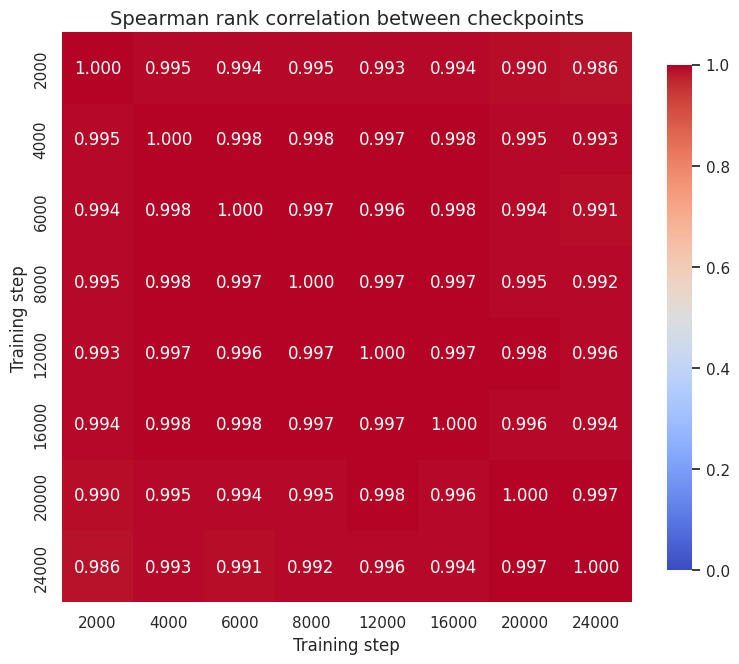

In [7]:
n_steps = len(steps)

if n_steps < 2:
    print("Only one checkpoint available so far – correlation matrix will be computed once more runs complete.")
    print("The cell below is ready and will execute automatically.")
else:
    corr_matrix = np.zeros((n_steps, n_steps))
    for i, s1 in enumerate(steps):
        for j, s2 in enumerate(steps):
            r, _ = stats.spearmanr(rank_df[s1], rank_df[s2])
            corr_matrix[i, j] = r

    corr_df = pd.DataFrame(corr_matrix, index=steps, columns=steps)

    fig, ax = plt.subplots(figsize=(max(6, n_steps), max(5, n_steps - 1)))
    sns.heatmap(
        corr_df, annot=True, fmt=".3f", cmap="coolwarm",
        vmin=0, vmax=1, ax=ax, square=True,
        cbar_kws={"shrink": 0.8}
    )
    ax.set_title("Spearman rank correlation between checkpoints", fontsize=14)
    ax.set_xlabel("Training step")
    ax.set_ylabel("Training step")
    plt.tight_layout()
    plt.show()

## 2 – Convergence to Final Checkpoint

How quickly does the ranking converge to the **last** available checkpoint?
(Once you have the fully-trained model this becomes the ground-truth ranking.)

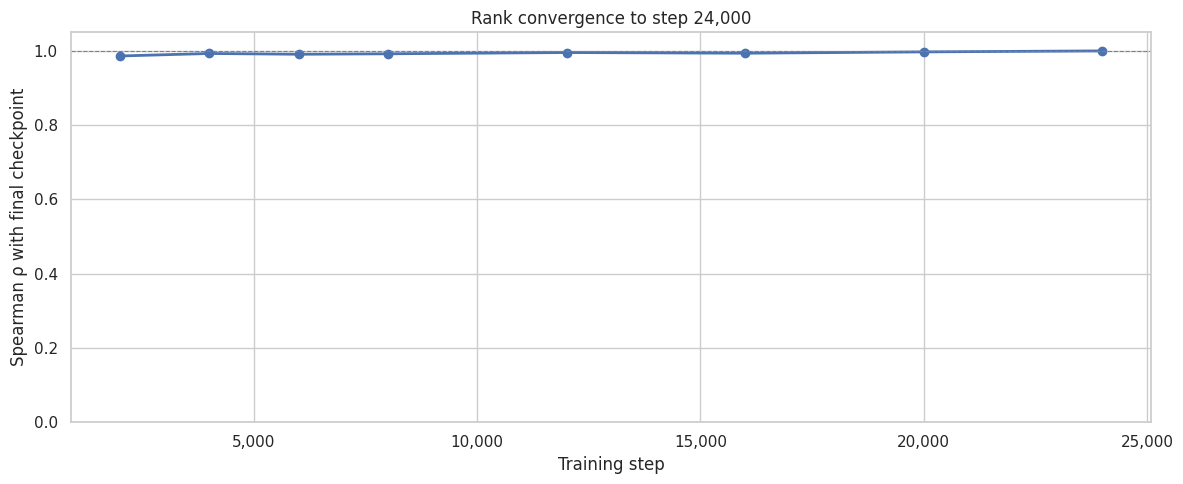

Spearman ρ vs. final checkpoint:
  step   2,000: ρ = 0.9863
  step   4,000: ρ = 0.9930
  step   6,000: ρ = 0.9910
  step   8,000: ρ = 0.9922
  step  12,000: ρ = 0.9956
  step  16,000: ρ = 0.9938
  step  20,000: ρ = 0.9973
  step  24,000: ρ = 1.0000


In [8]:
if n_steps < 2:
    print("Need at least 2 checkpoints.")
else:
    final_step = steps[-1]
    correlations = []
    for step in steps:
        r, _ = stats.spearmanr(rank_df[step], rank_df[final_step])
        correlations.append(r)

    fig, ax = plt.subplots()
    ax.plot(steps, correlations, marker="o", linewidth=2)
    ax.axhline(1.0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_xlabel("Training step")
    ax.set_ylabel("Spearman ρ with final checkpoint")
    ax.set_title(f"Rank convergence to step {final_step:,}")
    ax.set_ylim(0, 1.05)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
    plt.tight_layout()
    plt.show()

    print("Spearman ρ vs. final checkpoint:")
    for step, r in zip(steps, correlations):
        print(f"  step {step:>7,}: ρ = {r:.4f}")

## 3 – Top-K Stability

What fraction of the top-K placements at an early checkpoint are still in the top-K at the final checkpoint?

A high fraction means we could prune after that checkpoint.

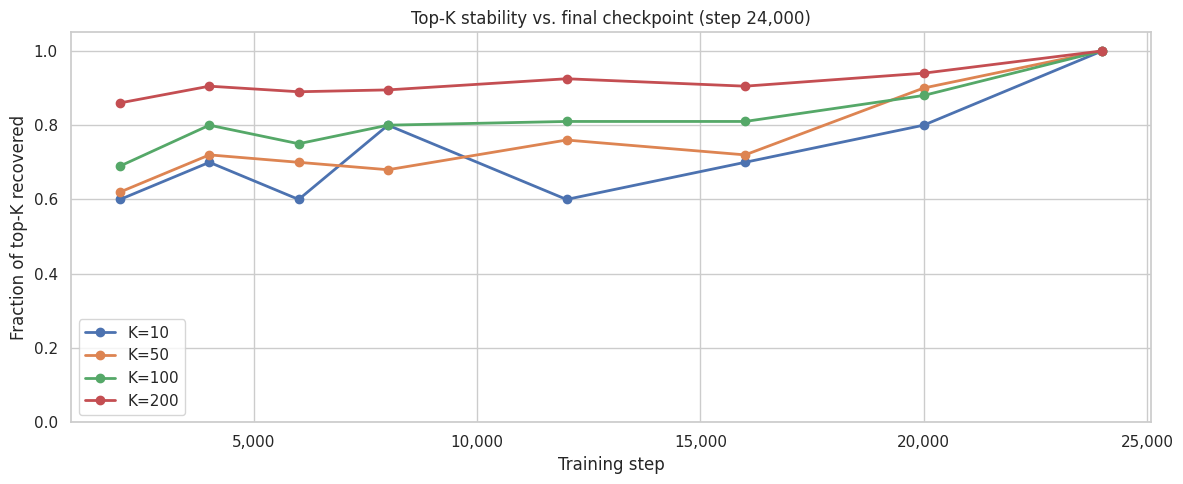

In [9]:
def top_k_overlap(ranks_early: pd.Series, ranks_final: pd.Series, k: int) -> float:
    """Fraction of top-K placements at `ranks_early` that are also in top-K at `ranks_final`."""
    top_early = set(ranks_early.nsmallest(k).index)
    top_final = set(ranks_final.nsmallest(k).index)
    return len(top_early & top_final) / k


if n_steps < 2:
    print("Need at least 2 checkpoints.")
else:
    final_step = steps[-1]

    fig, ax = plt.subplots()
    for k in TOP_K_VALUES:
        overlaps = [top_k_overlap(rank_df[step], rank_df[final_step], k) for step in steps]
        ax.plot(steps, overlaps, marker="o", linewidth=2, label=f"K={k}")

    ax.set_xlabel("Training step")
    ax.set_ylabel("Fraction of top-K recovered")
    ax.set_title(f"Top-K stability vs. final checkpoint (step {final_step:,})")
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
    plt.tight_layout()
    plt.show()

## 4 – Score Scatter: Early vs. Final Checkpoint

For each pair (early step, final step) we scatter-plot raw scores.
Points are coloured by the dominant mixer type in each placement.

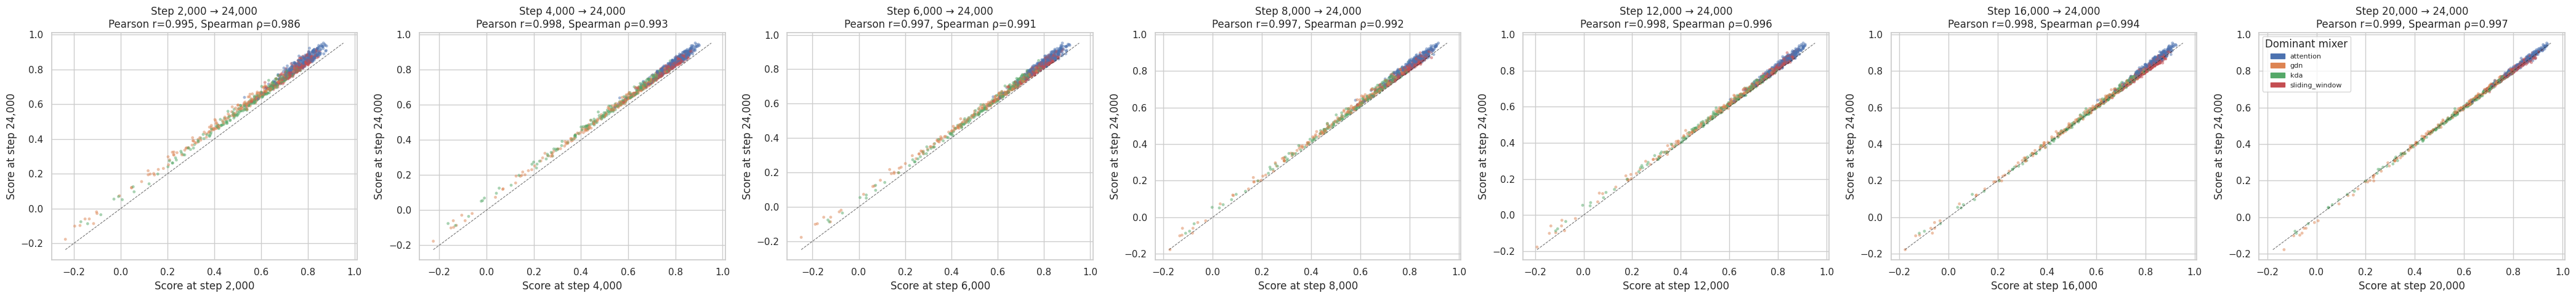

In [10]:
from collections import Counter

MIXER_COLORS = {
    "attention":      "#4C72B0",
    "gdn":            "#DD8452",
    "kda":            "#55A868",
    "sliding_window": "#C44E52",
    "other":          "#8172B2",
}

def dominant_mixer(placement_tuple: tuple) -> str:
    c = Counter(placement_tuple)
    return c.most_common(1)[0][0]


if n_steps < 2:
    print("Need at least 2 checkpoints.")
else:
    final_step = steps[-1]
    early_steps = steps[:-1]  # all but the last

    n_early = len(early_steps)
    fig, axes = plt.subplots(1, max(1, n_early), figsize=(6 * max(1, n_early), 5), squeeze=False)

    dominant = score_df.index.map(dominant_mixer)
    colors = dominant.map(lambda m: MIXER_COLORS.get(m, MIXER_COLORS["other"]))

    for ax, step in zip(axes[0], early_steps):
        r, p = stats.pearsonr(score_df[step], score_df[final_step])
        rho, _ = stats.spearmanr(score_df[step], score_df[final_step])

        ax.scatter(score_df[step], score_df[final_step],
                   c=colors, alpha=0.5, s=12, linewidths=0)
        ax.set_xlabel(f"Score at step {step:,}")
        ax.set_ylabel(f"Score at step {final_step:,}")
        ax.set_title(f"Step {step:,} → {final_step:,}\nPearson r={r:.3f}, Spearman ρ={rho:.3f}")

        # Add a 45° reference line across the range
        lo = min(score_df[step].min(), score_df[final_step].min())
        hi = max(score_df[step].max(), score_df[final_step].max())
        ax.plot([lo, hi], [lo, hi], "k--", linewidth=0.8, alpha=0.6)

    # Legend
    from matplotlib.patches import Patch
    handles = [Patch(color=c, label=m) for m, c in MIXER_COLORS.items() if m != "other"]
    axes[0][-1].legend(handles=handles, title="Dominant mixer", fontsize=8)

    plt.tight_layout()
    plt.show()

## 5 – Rank Displacement Distribution

For each placement, how much does its rank shift between an early checkpoint and the final one?
A tight distribution means the ranking is globally stable; a fat tail means a few placements move around a lot.

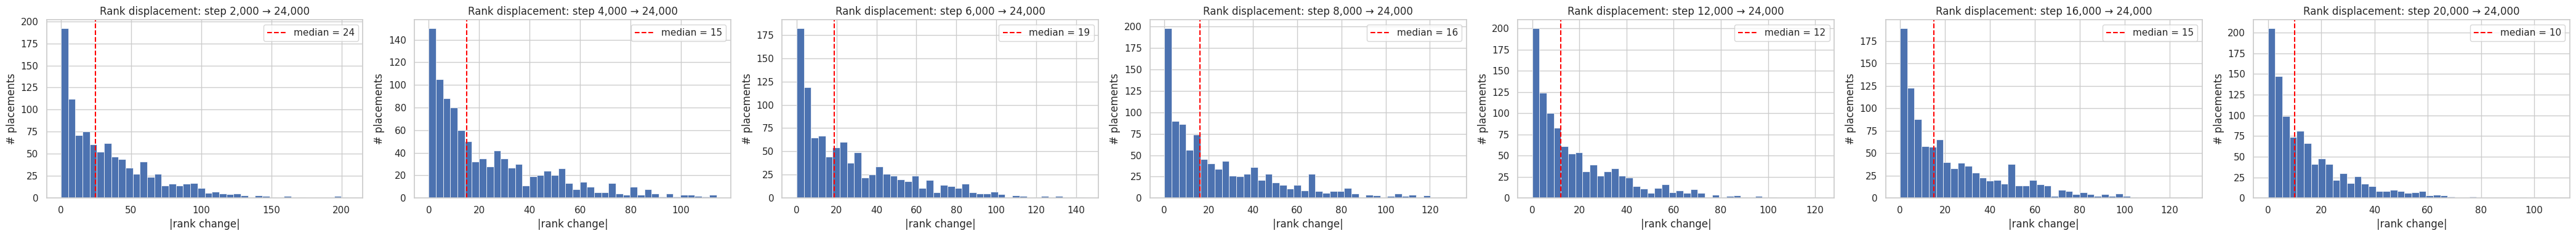

In [11]:
if n_steps < 2:
    print("Need at least 2 checkpoints.")
else:
    final_step = steps[-1]
    n_placements = len(rank_df)

    fig, axes = plt.subplots(1, max(1, n_early), figsize=(6 * max(1, n_early), 4), squeeze=False)

    for ax, step in zip(axes[0], early_steps):
        displacement = (rank_df[step] - rank_df[final_step]).abs()
        ax.hist(displacement, bins=40, edgecolor="white", linewidth=0.5)
        ax.axvline(displacement.median(), color="red", linestyle="--",
                   label=f"median = {displacement.median():.0f}")
        ax.set_xlabel("|rank change|")
        ax.set_ylabel("# placements")
        ax.set_title(f"Rank displacement: step {step:,} → {final_step:,}")
        ax.legend()

    plt.tight_layout()
    plt.show()

## 6 – Per-Placement Trajectories

For a selection of interesting placements, we plot their **rank** and **score** over time.
We pick:
- Top-5 at the final checkpoint
- Bottom-5 at the final checkpoint
- 5 most rank-unstable placements (largest displacement across checkpoints)

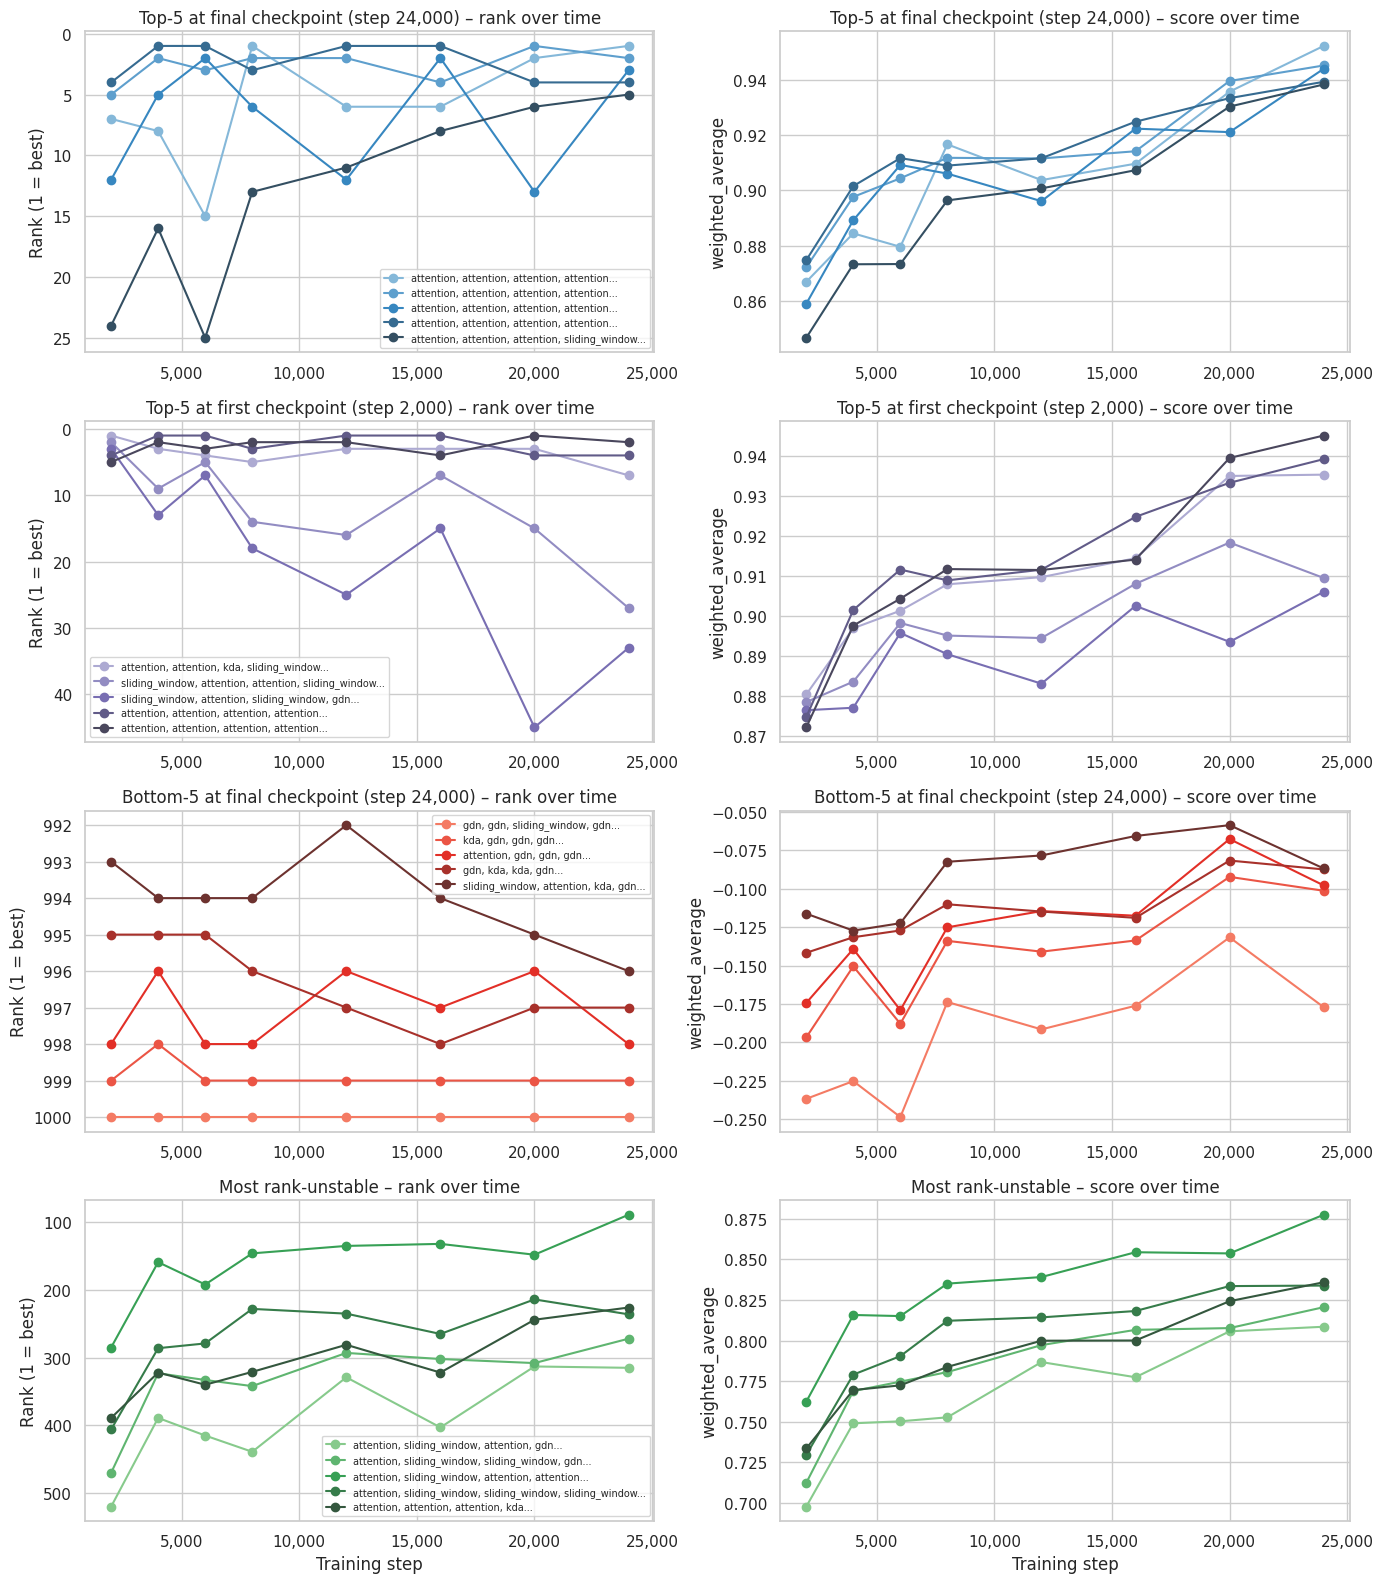

In [12]:
if n_steps < 2:
    print("Only one checkpoint – trajectory plot not available yet.")
else:
    final_step = steps[-1]
    first_step = steps[0]

    top5_final = rank_df[final_step].nsmallest(5).index.tolist()
    top5_first = rank_df[first_step].nsmallest(5).index.tolist()
    bot5 = rank_df[final_step].nlargest(5).index.tolist()

    max_disp = (rank_df.max(axis=1) - rank_df.min(axis=1))
    unstable5 = max_disp.nlargest(5).index.tolist()

    groups = [
        (f"Top-5 at final checkpoint (step {final_step:,})",  top5_final,  "Blues_d"),
        (f"Top-5 at first checkpoint (step {first_step:,})",  top5_first,  "Purples_d"),
        (f"Bottom-5 at final checkpoint (step {final_step:,})", bot5,      "Reds_d"),
        ("Most rank-unstable",                                  unstable5,  "Greens_d"),
    ]

    fig, axes = plt.subplots(len(groups), 2, figsize=(14, 4 * len(groups)))

    for row, (title, placements, palette) in enumerate(groups):
        ax_rank  = axes[row, 0]
        ax_score = axes[row, 1]
        colors = sns.color_palette(palette, len(placements))

        for p, c in zip(placements, colors):
            label = ", ".join(p[:4]) + ("..." if len(p) > 4 else "")
            ax_rank.plot(steps, rank_df.loc[p, steps],   marker="o", color=c, label=label)
            ax_score.plot(steps, score_df.loc[p, steps], marker="o", color=c, label=label)

        ax_rank.set_title(f"{title} – rank over time")
        ax_rank.set_ylabel("Rank (1 = best)")
        ax_rank.invert_yaxis()
        ax_rank.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

        ax_score.set_title(f"{title} – score over time")
        ax_score.set_ylabel(OBJECTIVE)
        ax_score.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

        ax_rank.legend(fontsize=7, ncol=1)

    for ax in axes[-1]:
        ax.set_xlabel("Training step")

    plt.tight_layout()
    plt.show()

## 6bis – Canary Trajectories (stratified by cost × score)

We select a small set of **canary** placements that are representative across the
cost–performance space, then track their rank and score over training.

**Cost** is computed from the per-layer mixer costs below (not stored in the results file).
Placements are binned by cost into `N_COST_BINS` equal-width bins.
Within each cost bin, `N_PER_BIN` canaries are chosen at uniform score percentiles
(e.g. best, median, worst inside that bin) using the **first** available checkpoint as reference.

In [13]:
# --- Canary configuration ---
MIXER_COSTS = {
    "attention":      1.0,
    "sliding_window": 0.156,
    "kda":            0.11,
    "gdn":            0.09,
}
N_COST_BINS = 8   # number of cost strata
N_PER_BIN   = 4   # canaries per bin (chosen at uniform score percentiles within the bin)

# -------------------------------------------------------------------
# Step 1: compute cost for every placement
# -------------------------------------------------------------------
def placement_cost(placement: tuple, costs: dict) -> float:
    return sum(costs.get(m) for m in placement)

cost_series = pd.Series(
    {p: placement_cost(p, MIXER_COSTS) for p in score_df.index},
    name="cost",
)

# -------------------------------------------------------------------
# Step 2: bin by cost, then pick canaries stratified by score
# Use the first checkpoint as the reference score for selection.
# -------------------------------------------------------------------
ref_step   = steps[0]
ref_scores = score_df[ref_step]

cost_min, cost_max = cost_series.min(), cost_series.max()
bin_edges = np.linspace(cost_min, cost_max, N_COST_BINS + 1)

canaries: list[tuple] = []          # placement tuples
canary_labels: list[str] = []       # human-readable label

for b in range(N_COST_BINS):
    lo, hi = bin_edges[b], bin_edges[b + 1]
    # include upper edge only for the last bin
    if b < N_COST_BINS - 1:
        mask = (cost_series >= lo) & (cost_series < hi)
    else:
        mask = (cost_series >= lo) & (cost_series <= hi)

    bin_placements = cost_series[mask].index
    if len(bin_placements) == 0:
        continue

    bin_scores = ref_scores.loc[bin_placements].sort_values()
    n_in_bin   = len(bin_scores)

    # Pick N_PER_BIN placements at uniform percentiles (0%, 50%, 100% for N=3, etc.)
    if N_PER_BIN == 1:
        percentile_positions = [0.5]
    else:
        percentile_positions = [i / (N_PER_BIN - 1) for i in range(N_PER_BIN)]

    for pct in percentile_positions:
        idx = int(round(pct * (n_in_bin - 1)))
        placement = bin_scores.index[idx]
        cost_val  = cost_series[placement]
        score_val = bin_scores.iloc[idx]
        canaries.append(placement)
        canary_labels.append(
            f"cost={cost_val:.3f} score={score_val:.3f}\n"
            + ", ".join(placement[:3]) + ("…" if len(placement) > 3 else "")
        )

print(f"Selected {len(canaries)} canaries across {N_COST_BINS} cost bins × {N_PER_BIN} score percentiles\n")
print(f"{'Bin':>4}  {'Cost range':>18}  {'Score pct':>10}  {'Cost':>7}  {'Score':>7}  Placement (first 6)")
print("-" * 80)
for i, (p, label) in enumerate(zip(canaries, canary_labels)):
    b = i // N_PER_BIN
    pct_idx = i % N_PER_BIN
    lo, hi = bin_edges[b], bin_edges[b + 1]
    pct_label = ["low", "mid", "high"][pct_idx] if N_PER_BIN == 3 else f"{100*pct_idx/(N_PER_BIN-1):.0f}%"
    print(f"{b:>4}  [{lo:.3f}, {hi:.3f}]  {pct_label:>10}  "
          f"{cost_series[p]:>7.3f}  {ref_scores[p]:>7.4f}  "
          + " ".join(p[:6]) + ("…" if len(p) > 6 else ""))

Selected 32 canaries across 8 cost bins × 4 score percentiles

 Bin          Cost range   Score pct     Cost    Score  Placement (first 6)
--------------------------------------------------------------------------------
   0  [4.546, 9.755]          0%    4.578  -0.2368  gdn gdn sliding_window gdn kda gdn…
   0  [4.546, 9.755]         33%    7.348   0.4429  sliding_window sliding_window kda kda kda kda…
   0  [4.546, 9.755]         67%    6.758   0.6412  sliding_window sliding_window gdn sliding_window gdn sliding_window…
   0  [4.546, 9.755]        100%    8.952   0.8138  sliding_window sliding_window sliding_window gdn sliding_window sliding_window…
   1  [9.755, 14.965]          0%   11.800   0.1410  gdn gdn attention attention attention kda…
   1  [9.755, 14.965]         33%   13.106   0.5838  attention gdn kda attention gdn kda…
   1  [9.755, 14.965]         67%   10.826   0.7070  attention kda sliding_window sliding_window sliding_window gdn…
   1  [9.755, 14.965]        100%   1

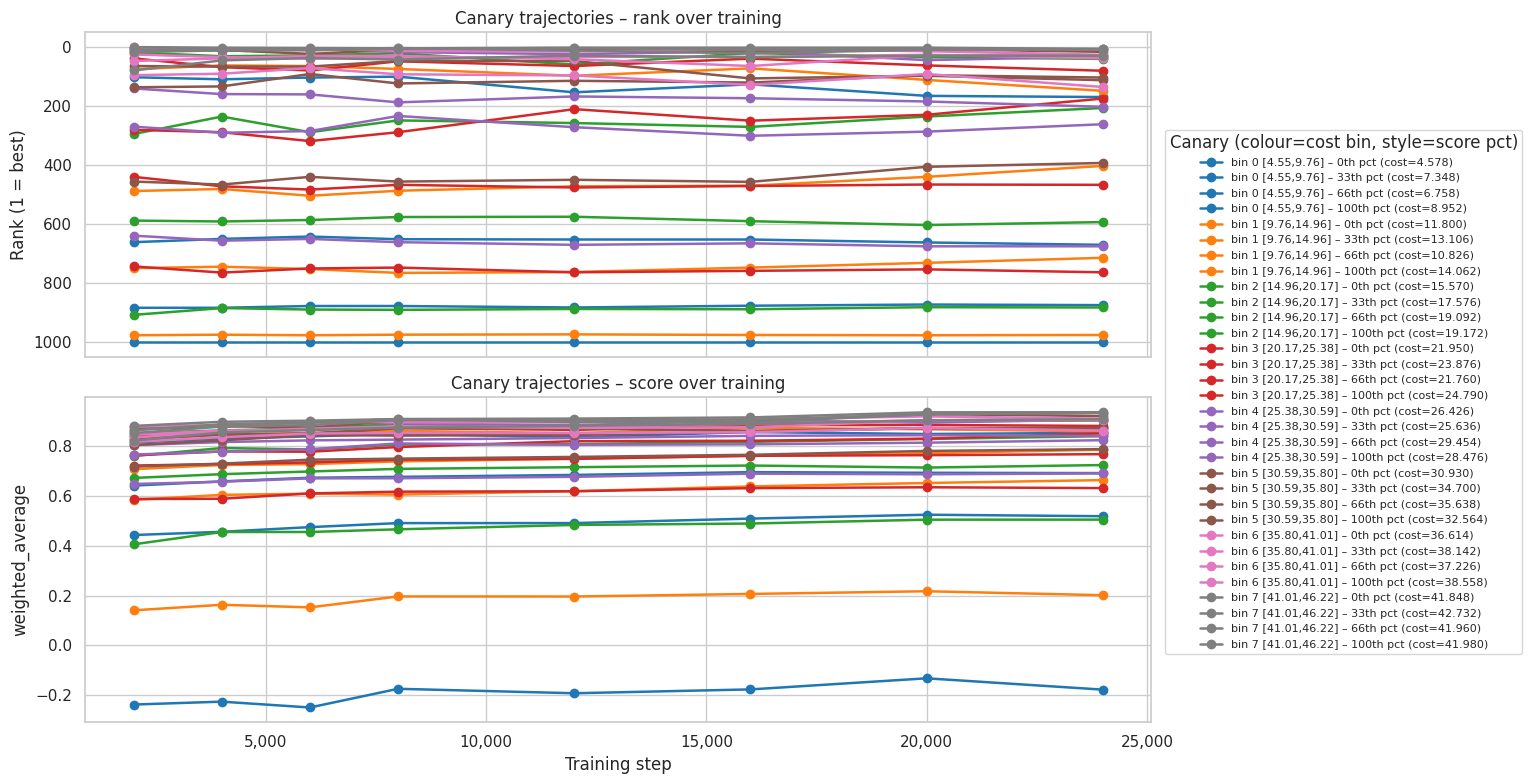

In [14]:
if n_steps < 2:
    print("Only one checkpoint – canary trajectories not available yet.")
else:
    fig, (ax_rank, ax_score) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    # One colour per cost bin, one line style per score percentile within the bin
    bin_colors    = sns.color_palette("tab10", N_COST_BINS)
    pct_linestyles = ["--", "-", ":"] if N_PER_BIN == 3 else ["-"] * N_PER_BIN
    pct_labels     = (["low score", "mid score", "high score"]
                      if N_PER_BIN == 3
                      else [f"{100*i//(N_PER_BIN-1)}th pct" for i in range(N_PER_BIN)])

    for b in range(N_COST_BINS):
        lo, hi = bin_edges[b], bin_edges[b + 1]
        color  = bin_colors[b]
        bin_canaries = canaries[b * N_PER_BIN : (b + 1) * N_PER_BIN]

        for p, ls, pct_label in zip(bin_canaries, pct_linestyles, pct_labels):
            cost_val  = cost_series[p]
            label = f"bin {b} [{lo:.2f},{hi:.2f}] – {pct_label} (cost={cost_val:.3f})"
            ax_rank.plot(steps, rank_df.loc[p, steps],  marker="o", color=color,
                         linestyle=ls, linewidth=1.8, label=label)
            ax_score.plot(steps, score_df.loc[p, steps], marker="o", color=color,
                          linestyle=ls, linewidth=1.8, label=label)

    ax_rank.invert_yaxis()
    ax_rank.set_ylabel("Rank (1 = best)")
    ax_rank.set_title("Canary trajectories – rank over training")
    ax_rank.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

    ax_score.set_ylabel(OBJECTIVE)
    ax_score.set_xlabel("Training step")
    ax_score.set_title("Canary trajectories – score over training")
    ax_score.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

    # Single shared legend outside the plots
    handles, labels = ax_rank.get_legend_handles_labels()
    fig.legend(handles, labels, loc="center right", bbox_to_anchor=(1.28, 0.5),
               fontsize=8, title="Canary (colour=cost bin, style=score pct)")

    plt.tight_layout()
    plt.show()

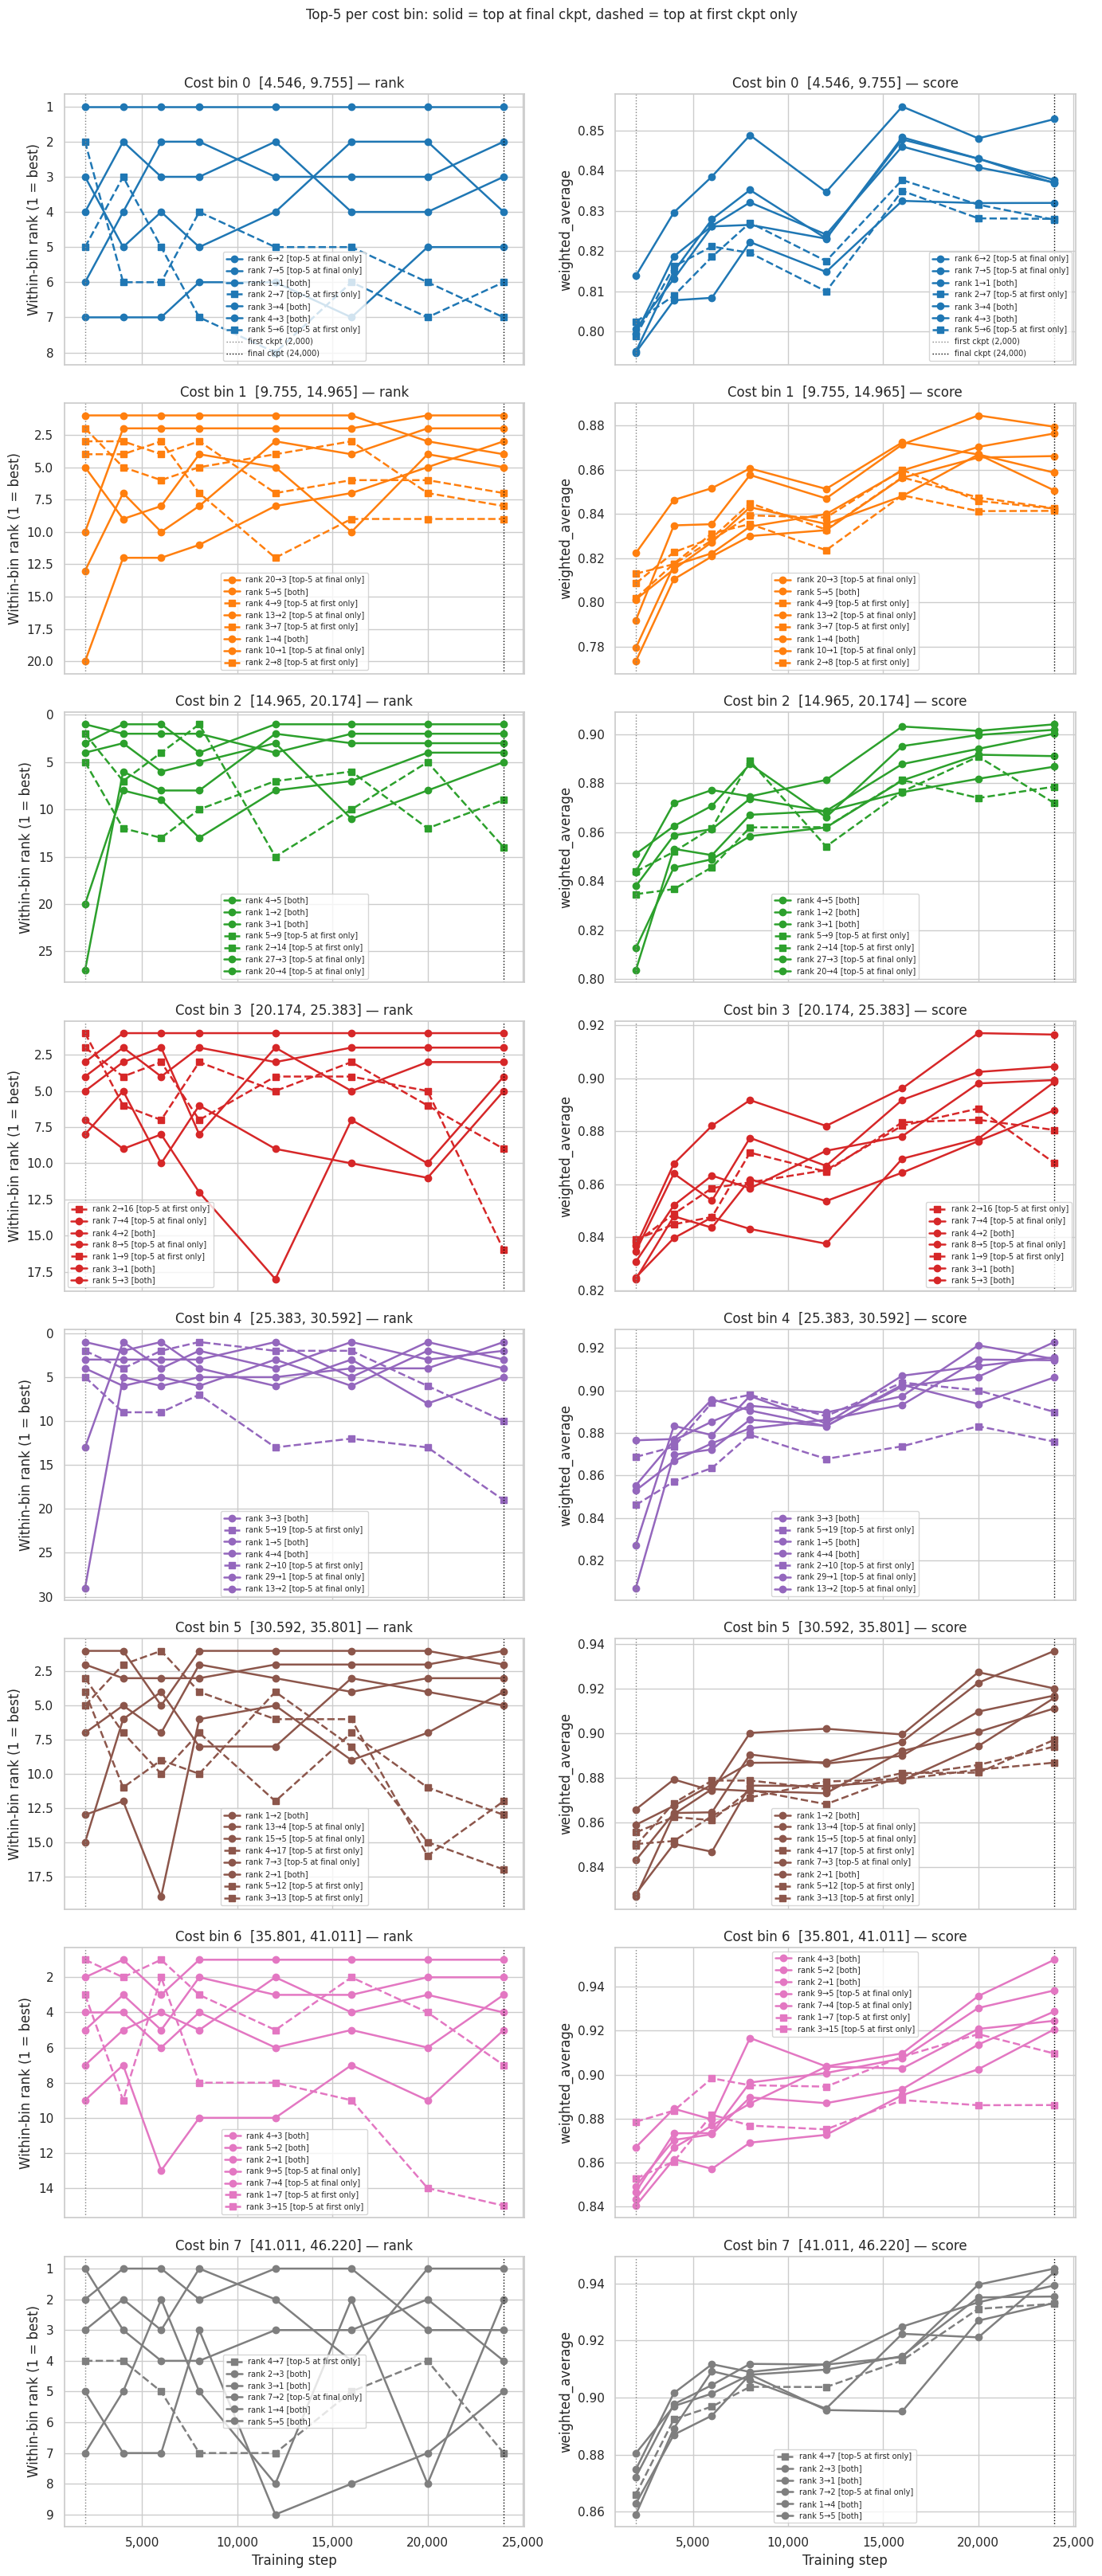

In [ ]:
TOP_K_PER_BIN = 5

if n_steps < 2:
    print("Only one checkpoint – canary trajectories not available yet.")
else:
    bin_colors = sns.color_palette("tab10", N_COST_BINS)

    # Pre-compute within-bin ranks for every step
    bin_rank_dfs: dict[int, pd.DataFrame] = {}
    bin_members:  dict[int, list] = {}

    for b in range(N_COST_BINS):
        lo, hi = bin_edges[b], bin_edges[b + 1]
        mask = (cost_series >= lo) & (cost_series <= hi) if b == N_COST_BINS - 1 else (cost_series >= lo) & (cost_series < hi)
        members = cost_series[mask].index.tolist()
        bin_members[b] = members
        bin_rank_dfs[b] = score_df.loc[members, steps].rank(ascending=False, method="average")

    fig, axes = plt.subplots(N_COST_BINS, 2, figsize=(14, 4 * N_COST_BINS), sharex=True)

    for b in range(N_COST_BINS):
        lo, hi = bin_edges[b], bin_edges[b + 1]
        color  = bin_colors[b]
        ax_rank  = axes[b, 0]
        ax_score = axes[b, 1]

        topk_final = set(bin_rank_dfs[b][final_step].nsmallest(TOP_K_PER_BIN).index)
        topk_first = set(bin_rank_dfs[b][first_step].nsmallest(TOP_K_PER_BIN).index)
        all_tracked = topk_final | topk_first

        for p in all_tracked:
            in_final = p in topk_final
            in_first = p in topk_first

            if in_final and in_first:
                ls, marker, zorder = "-",  "o", 3
                tag = "both"
            elif in_final:
                ls, marker, zorder = "-",  "o", 2
                tag = f"top-{TOP_K_PER_BIN} at final only"
            else:
                ls, marker, zorder = "--", "s", 1
                tag = f"top-{TOP_K_PER_BIN} at first only"

            rank_at_first = int(bin_rank_dfs[b].loc[p, first_step])
            rank_at_final = int(bin_rank_dfs[b].loc[p, final_step])
            label = f"rank {rank_at_first}→{rank_at_final} [{tag}]"

            ax_rank.plot(steps, bin_rank_dfs[b].loc[p, steps], marker=marker, color=color,
                         linestyle=ls, linewidth=1.8, zorder=zorder, label=label)
            ax_score.plot(steps, score_df.loc[p, steps], marker=marker, color=color,
                          linestyle=ls, linewidth=1.8, zorder=zorder, label=label)

        # Vertical lines marking the two selection checkpoints
        for ax in (ax_rank, ax_score):
            ax.axvline(first_step, color="gray", linestyle=":", linewidth=1,
                       label=f"first ckpt ({first_step:,})" if b == 0 else "_nolegend_")
            ax.axvline(final_step, color="black", linestyle=":", linewidth=1,
                       label=f"final ckpt ({final_step:,})" if b == 0 else "_nolegend_")

        ax_rank.invert_yaxis()
        ax_rank.set_ylabel("Within-bin rank (1 = best)")
        ax_rank.set_title(f"Cost bin {b}  [{lo:.3f}, {hi:.3f}] — rank")
        ax_rank.legend(fontsize=7)
        ax_rank.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

        ax_score.set_ylabel(OBJECTIVE)
        ax_score.set_title(f"Cost bin {b}  [{lo:.3f}, {hi:.3f}] — score")
        ax_score.legend(fontsize=7)
        ax_score.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

    for ax in axes[-1]:
        ax.set_xlabel("Training step")

    fig.suptitle(
        f"Top-{TOP_K_PER_BIN} per cost bin: solid = top at final ckpt, dashed = top at first ckpt only",
        fontsize=12, y=1.01,
    )
    plt.tight_layout()
    plt.show()

## 7 – Mixer-Type Bias Over Training

Do attention-heavy placements dominate early but lose ground later as GDN/KDA come into their own?

We group placements by dominant mixer type and plot the average **rank** of each group at each checkpoint.

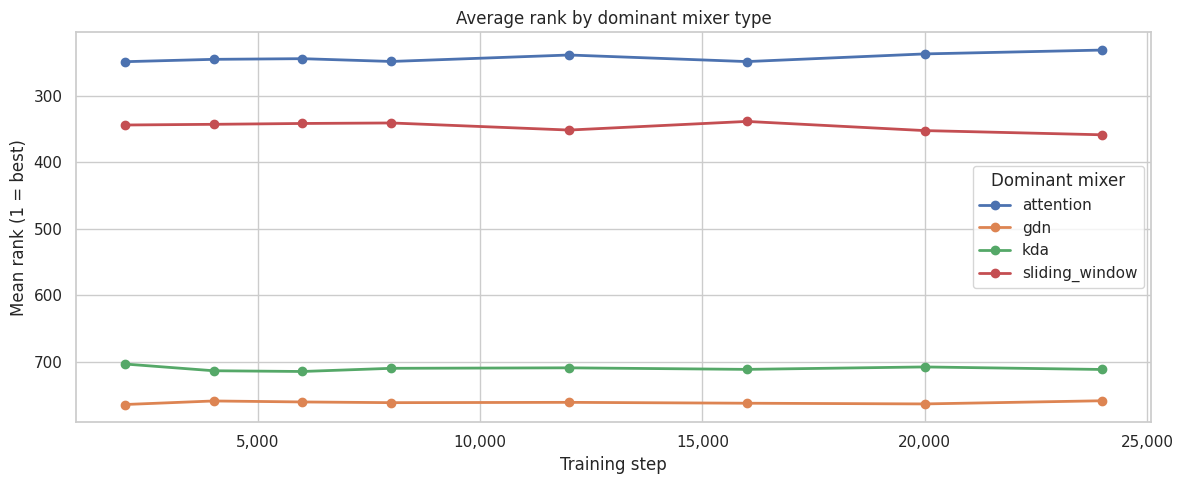


Mean rank by dominant mixer (lower = better):
step                  2000        4000        6000        8000       12000       16000       20000       24000
dominant_mixer                                                                                                
attention       248.977358  245.418868  244.422642  248.622642  238.901887  248.792453  237.271698  231.475472
gdn             764.273128  758.916300  760.409692  761.466960  760.986784  762.312775  763.361233  758.599119
kda             703.350000  713.504167  714.612500  709.829167  709.116667  711.433333  707.770833  711.600000
sliding_window  344.130597  343.093284  341.820896  341.055970  351.712687  338.735075  352.518657  358.854478


In [16]:
dominant_series = pd.Series(
    {p: dominant_mixer(p) for p in score_df.index},
    name="dominant_mixer"
)

rank_with_mixer = rank_df.copy()
rank_with_mixer["dominant_mixer"] = dominant_series

mean_rank_by_mixer = rank_with_mixer.groupby("dominant_mixer")[steps].mean()

fig, ax = plt.subplots()
for mixer in mean_rank_by_mixer.index:
    color = MIXER_COLORS.get(mixer, MIXER_COLORS["other"])
    ax.plot(steps, mean_rank_by_mixer.loc[mixer], marker="o",
            color=color, linewidth=2, label=mixer)

ax.invert_yaxis()
ax.set_xlabel("Training step")
ax.set_ylabel("Mean rank (1 = best)")
ax.set_title("Average rank by dominant mixer type")
ax.legend(title="Dominant mixer")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

print("\nMean rank by dominant mixer (lower = better):")
print(mean_rank_by_mixer.to_string())

## 8 – Single-Checkpoint Summary (available now)

Until more checkpoints are available, this section provides a useful baseline:
the score distribution at the **current** checkpoint, the top placements, and their composition.

=== Step 2,000 ===

Placements evaluated: 1000
Score range:  [-0.2368, 0.8805]
Mean ± std:   0.6499 ± 0.1813


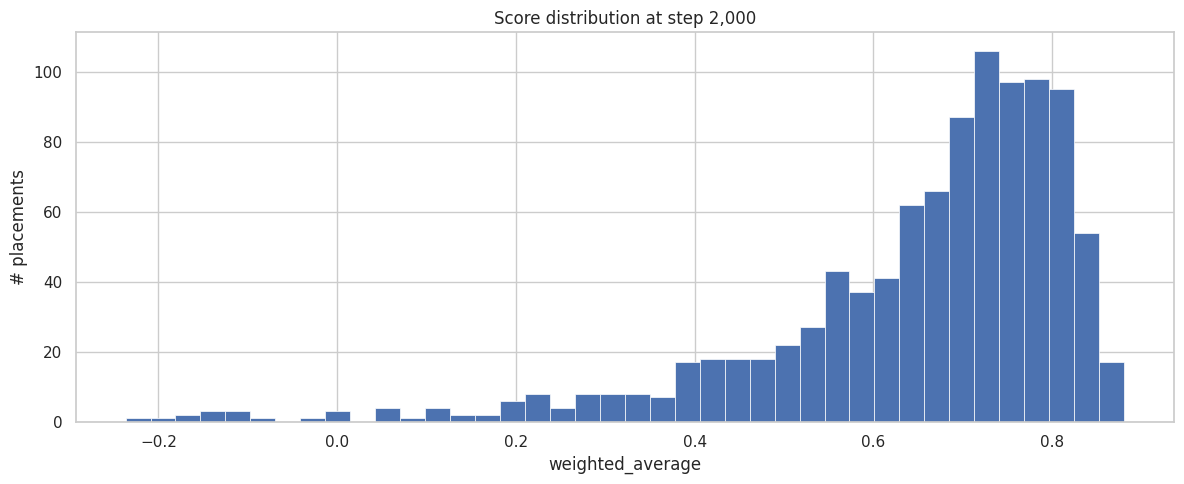

In [ ]:
current_step = steps[0]
scores = score_df[current_step].sort_values(ascending=False)

print(f"=== Step {current_step:,} ===\n")
print(f"Placements evaluated: {len(scores)}")
print(f"Score range:  [{scores.min():.4f}, {scores.max():.4f}]")
print(f"Mean ± std:   {scores.mean():.4f} ± {scores.std():.4f}")

fig, ax = plt.subplots()
ax.hist(scores.values, bins=40, edgecolor="white", linewidth=0.5)
ax.set_xlabel(OBJECTIVE)
ax.set_ylabel("# placements")
ax.set_title(f"Score distribution at step {current_step:,}")
plt.tight_layout()
plt.show()

In [ ]:
# Top-20 placements with composition summary
print(f"Top 20 placements at step {current_step:,}:\n")
print(f"{'Rank':>5}  {'Score':>8}  {'#attn':>6}  {'#gdn':>5}  {'#kda':>5}  {'#sw':>5}  Placement (first 12 layers)")
print("-" * 90)

for rank_i, (placement, score) in enumerate(scores.head(20).items(), start=1):
    c = Counter(placement)
    preview = " ".join(m[:2] for m in placement[:12]) + (" ..." if len(placement) > 12 else "")
    print(f"{rank_i:>5}  {score:>8.4f}  {c.get('attention',0):>6}  {c.get('gdn',0):>5}  "
          f"{c.get('kda',0):>5}  {c.get('sliding_window',0):>5}  {preview}")

Top 20 placements at step 2,000:

 Rank     Score   #attn   #gdn   #kda    #sw  Placement (first 12 layers)
------------------------------------------------------------------------------------------
    1    0.8805      41      1      1      5  at at kd sl at at at at sl at gd sl ...
    2    0.8786      37      1      2      8  sl at at sl at at at at at gd at at ...
    3    0.8765      25      1      1     21  sl at sl gd at at sl sl sl at sl sl ...
    4    0.8748      43      0      0      5  at at at at at at at at at at at at ...
    5    0.8722      46      0      2      0  at at at at at at at kd at at at at ...
    6    0.8688      24      3      0     21  sl at at at sl at at sl at sl sl at ...
    7    0.8670      36      0      2     10  at at at at at at at kd at at at sl ...
    8    0.8661      42      0      5      1  at at at kd at at at at at at at at ...
    9    0.8660      30      3      1     14  at at kd at at at at sl sl gd gd sl ...
   10    0.8628      41    

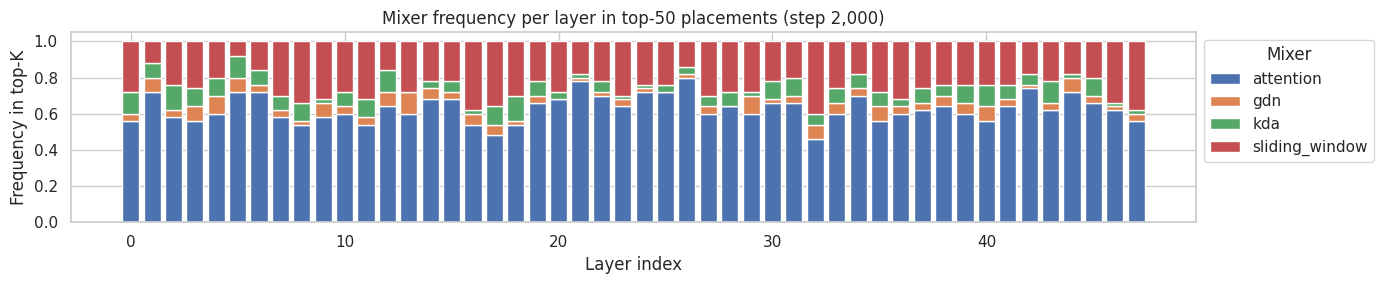

In [ ]:
# Per-layer mixer frequency among top-K placements
K = 50
top_placements = [p for p, _ in scores.head(K).items()]
n_layers = len(top_placements[0])

all_mixers_seen = sorted(set(m for p in score_df.index for m in p))
freq = np.zeros((len(all_mixers_seen), n_layers))
for p in top_placements:
    for layer_i, mixer in enumerate(p):
        freq[all_mixers_seen.index(mixer), layer_i] += 1
freq /= K

fig, ax = plt.subplots(figsize=(14, 3))
bottom = np.zeros(n_layers)
for mi, mixer in enumerate(all_mixers_seen):
    color = MIXER_COLORS.get(mixer, MIXER_COLORS["other"])
    ax.bar(range(n_layers), freq[mi], bottom=bottom, label=mixer, color=color)
    bottom += freq[mi]

ax.set_xlabel("Layer index")
ax.set_ylabel("Frequency in top-K")
ax.set_title(f"Mixer frequency per layer in top-{K} placements (step {current_step:,})")
ax.legend(title="Mixer", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()